In [1]:
# Import packages that will be used
import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumRegister

import bosonic_qiskit

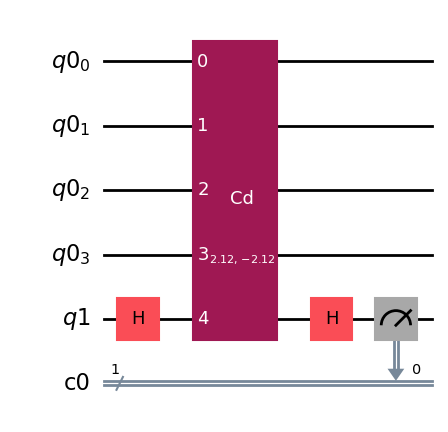

In [2]:
# To prepare a cat state, we first set our initial parameters: we need one qumode and one ancillary qubit. We will also
# need to set a cutoff for our qumode.face
Nmodes=1 #We need 1 qumode (the bosonic mode that will become the cat state)
Nqubits = 1 # We need 1 auxiliary qubit (the helper qubit to create superposition)
cutoff = 2**4 # The photon number at which to truncate the Hilbert space. Our basis will consist of Fock states |0> to |cutoff-1>
alpha = 3/np.sqrt(2) #2.12 displacement amplitude for our coherent states

# Instantiate the Qumode register
qmr = bosonic_qiskit.QumodeRegister(num_qumodes=Nmodes, num_qubits_per_qumode=int(np.ceil(np.log2(cutoff))))

# Instantiate a Qubit and Classical register
qbr = QuantumRegister(Nqubits)
cbr = ClassicalRegister(Nqubits)

# Initialize a CVCircuit, which includes both the qumode register as well as the qubit register
circuit = bosonic_qiskit.CVCircuit(qmr, qbr, cbr)

# Compose cat state prep circuit
circuit.h(qbr[0])
circuit.cv_c_d(alpha,qmr[0],qbr[0])
circuit.h(qbr[0])
circuit.measure(qbr[0],cbr[0])

# Now draw the circuit using Qiskit's draw() function
circuit.draw(scale=1, output = 'mpl', fold = 32, filename = 'figures/Catcircuit.png')

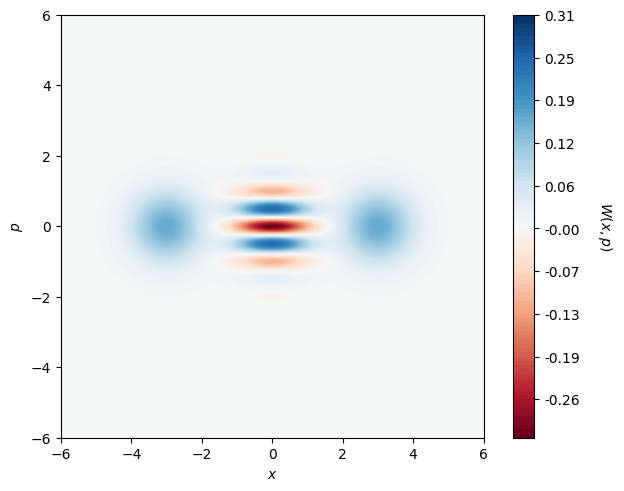

In [3]:
# Now simulate the circuit to retrieve the final density matrix.
stateop, _, _ = bosonic_qiskit.util.simulate(circuit)

# Use Bosonic Qiskit's built-in plot_wigner function, which traces out the qubit and displays the Wigner (phase-space) 
# representation of the qumode state.
fig = bosonic_qiskit.wigner.plot_wigner(circuit, stateop, dpi = 300)

In [4]:
#BOSE HUBBARD MODEL SIMULATION

# Let's first define a function which constructs our approximation to e^{-iH*dt}
def createU2U1(Nsites,Nbosons, cutoff, U, J, dt):
    from qiskit.converters import circuit_to_gate
    from qiskit.circuit import Parameter
    
    qmr = bosonic_qiskit.QumodeRegister(num_qumodes=Nsites, num_qubits_per_qumode=int(np.ceil(np.log2(cutoff)))) # Create a qumode register with Nsites qumodes, each with enough qubits to represent the cutoff Fock states
    
    circuit = bosonic_qiskit.CVCircuit(qmr) # Create a CV circuit with the qumode register

    # First apply U1: Apply beamsplitters in brickwork layout
    theta = -J*dt # Beamsplitter angle for the hopping term 
    for i in range(0,len(qmr)-1,2):           # Apply beamsplitters in a brickwork pattern: first between modes 0&1, 2&3, etc.
        circuit.cv_bs(-theta,qmr[i],qmr[i+1]) # Apply beamsplitter with angle -theta between modes i and i+1
    for i in range(1,len(qmr)-1,2):           # Then apply beamsplitters between modes 1&2, 3&4, etc.
        circuit.cv_bs(-theta,qmr[i],qmr[i+1])
        
    # Now apply U2: Use SNAP gate for each site and Fock state
    theta = (U/2)*dt
    for i in range(0,len(qmr)):  
        for n in range(2,cutoff): 
            circuit.cv_snap(-theta*n*(n-1),n,qmr[i]) # Apply SNAP with phase proportional to n*(n-1)
            
    return circuit_to_gate(circuit,label = 'U2U1')

In [5]:
# Let's simulate a Bose-Hubbard model with Nsites for the simple case where we have Nbosons loaded into the lattice
Nsites = 4
Nbosons = 4
cutoff = Nbosons + 1

# Initialize the qumode register
qmr = bosonic_qiskit.QumodeRegister(num_qumodes=Nsites, num_qubits_per_qumode=int(np.ceil(np.log2(cutoff))))
circuit = bosonic_qiskit.CVCircuit(qmr)

# Choose parameters
J = 0.1
U = 1
dt = 0.2 
t_array = np.arange(0,13*dt,dt)

# Create U2U1, which carries out a single time step of length dt
U2U1 = createU2U1(Nsites, Nbosons, cutoff, U, J, dt)

# Initialize the left-most and right-most mode to each have two bosons initially
circuit.cv_initialize(2, qmr[0])
circuit.cv_initialize(2, qmr[3])

# Loop through each time step and simulate
occupancy_list = np.zeros((len(t_array),Nsites)) #Initialize an array to store the occupancy of each site at each time step
for i in range(0,len(t_array)): 
    print('Timestep' + str(int(i+1)) + '/' + str(len(t_array)))
    circuit.append(U2U1,qmr.qubits)
    stateop, _, _ = bosonic_qiskit.util.simulate(circuit)
    
    # Print out occupancy
    occupancy, _ = bosonic_qiskit.util.stateread(stateop, 0, Nsites, cutoff, verbose=False,little_endian=True)
    occupancy_list[i,:]=np.array(occupancy[0])
    
    
occupancy_largeJ = occupancy_list

Timestep1/13
Timestep2/13
Timestep3/13
Timestep4/13
Timestep5/13
Timestep6/13
Timestep7/13
Timestep8/13
Timestep9/13
Timestep10/13
Timestep11/13
Timestep12/13
Timestep13/13


In [ ]:
# Heat map thing

plt.set_cmap("magma")

fig = plt.figure(figsize = (4,8))
plt.pcolormesh([0,1,2,3],np.arange(0,len(t_array)),occupancy_list,linewidth=0,rasterized=True,shading='auto')
plt.title("$J=$" + str(J) + ", $U=$" + str(0.1))
plt.xticks([0,1,2,3])
plt.xlabel("Qumode")
plt.ylabel("Time ($dt$)")
plt.clim(0,2)

cbar = plt.colorbar(orientation='vertical',ax=plt.gca())
cbar.ax.get_yaxis().labelpad = 20
cbar.set_ticks([0,0.5,1,1.5,2])
cbar.set_label("Mode occupation", rotation=270)
plt.tight_layout()

In [ ]:
# As usual, first define how many qumodes we want, and how many qubits we should use to represent each (equivalent to choosing a cutoff)
num_qumodes = 1
num_qubits_per_qumode = 4
qmr = bosonic_qiskit.QumodeRegister(num_qumodes, num_qubits_per_qumode)
circuit = bosonic_qiskit.CVCircuit(qmr)

# First initialize the qumode in Fock state |3>
circuit.cv_initialize(3, qmr[0])

# Let's now apply a displacement gate. Bosonic Qiskit allows a user to specify the gate duration in user-specified units (which
# will be used to calculate the loss probability at each time step). Let's go with a 100ns gate duration.
circuit.cv_d(1.5, qmr[0], duration=100, unit="ns")

# Now set a loss rate -- make it large enough such that we can actually see the loss
photon_loss_rate = 0.02 # This is a loss rate in units of 1/ns kappa
time_unit = "ns"
noise_pass = bosonic_qiskit.kraus.PhotonLossNoisePass(photon_loss_rates=photon_loss_rate, circuit=circuit, time_unit=time_unit)

# The noise pass can then be passed into simulate
state, result, _ = bosonic_qiskit.util.simulate(circuit, noise_passes=noise_pass)


# ...existing code...
import os
os.makedirs('figures', exist_ok=True)

anim = bosonic_qiskit.animate.animate_wigner(
    circuit,
    animation_segments=200,
    noise_passes=noise_pass
)
anim.save('figures/photon_loss.gif', writer='pillow')  # requires Pillow installed
  

Bose-Hubbard simulation: 4 sites, 4 bosons
J=1.0, U=0.1, dt=0.2, 13 steps
Bipartition: A=sites[0,2), B=sites[2,4)
Initial state: [2, 0, 0, 2]

  Timestep 13/13  (t = 2.400)
Boson number conservation check:
  min=4.0000, max=4.0000  (should be 4)
Entropy at t=0 (should be ~0): 0.044889
Max entropy reached: 1.9739 nats



C:\Users\DELL\AppData\Local\Temp\ipykernel_12728\1061604017.py:274: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


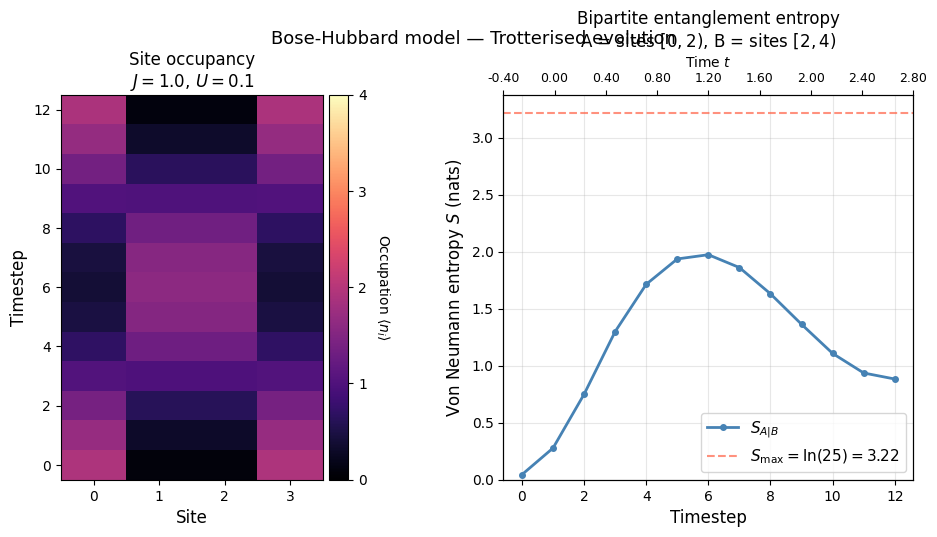

In [13]:
"""
Bose-Hubbard Model Simulation with Bipartite Entanglement Entropy
=================================================================
Simulates N bosons on a 1D lattice using bosonic_qiskit (CV circuit framework).
Tracks site occupancies and von Neumann entanglement entropy between the
left half (sites 0..cut-1) and right half (sites cut..Nsites-1) over time.

Physical model:
    H = -J * sum_<i,j> (a†_i a_j + h.c.) + (U/2) * sum_i n_i(n_i - 1)

Trotterisation:
    U2U1 = exp(-i U2 dt) * exp(-i U1 dt)
    U1: beamsplitters (hopping, brickwork layout)
    U2: SNAP gates (on-site interaction)
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.linalg import svd
import bosonic_qiskit
from qiskit.converters import circuit_to_gate


# ── Trotter step ──────────────────────────────────────────────────────────────

def build_trotter_step(Nsites, cutoff, U, J, dt):
    """
    Construct one Trotter step gate U2·U1 ≈ exp(-i H dt).

    U1: beamsplitters in brickwork layout  → hopping term
    U2: SNAP gates per site                → interaction term

    Parameters
    ----------
    Nsites  : int   — number of lattice sites (qumodes)
    cutoff  : int   — Fock space truncation (max occupation + 1)
    U       : float — on-site interaction strength
    J       : float — hopping amplitude
    dt      : float — Trotter step size

    Returns
    -------
    gate : Qiskit Gate representing one Trotter step
    """
    n_qubits_per_mode = int(np.ceil(np.log2(cutoff)))
    qmr = bosonic_qiskit.QumodeRegister(
        num_qumodes=Nsites,
        num_qubits_per_qumode=n_qubits_per_mode
    )
    circuit = bosonic_qiskit.CVCircuit(qmr)

    # U1: brickwork beamsplitters (hopping)
    theta_bs = -J * dt
    for i in range(0, Nsites - 1, 2):        # even bonds: (0,1), (2,3), ...
        circuit.cv_bs(-theta_bs, qmr[i], qmr[i + 1])
    for i in range(1, Nsites - 1, 2):        # odd bonds:  (1,2), (3,4), ...
        circuit.cv_bs(-theta_bs, qmr[i], qmr[i + 1])

    # U2: SNAP gates (on-site interaction)
    theta_snap = (U / 2) * dt
    for i in range(Nsites):
        for n in range(2, cutoff):            # phase ∝ n(n-1), zero for n<2
            circuit.cv_snap(-theta_snap * n * (n - 1), n, qmr[i])

    return circuit_to_gate(circuit, label='U2U1')


# ── Entanglement entropy ──────────────────────────────────────────────────────

def von_neumann_entropy(stateop, Nsites, cutoff, cut=None):
    """
    Bipartite von Neumann entropy S = -Tr(rho_A log rho_A).

    Uses Schmidt decomposition on the raw statevector — no stateread needed.
    Qiskit uses little-endian qubit ordering: qumode i lives in qubits
    [i*n_q, (i+1)*n_q), so A = qumodes 0..cut-1, B = qumodes cut..Nsites-1.

    Parameters
    ----------
    stateop : Qiskit Statevector from bosonic_qiskit.util.simulate
    Nsites  : int — total number of sites
    cutoff  : int — Fock truncation
    cut     : int — bipartition index (default: Nsites // 2)

    Returns
    -------
    entropy : float — von Neumann entropy in nats
    """
    if cut is None:
        cut = Nsites // 2

    n_qubits_per_mode = int(np.ceil(np.log2(cutoff)))
    n_qubits_A = cut * n_qubits_per_mode
    n_qubits_B = (Nsites - cut) * n_qubits_per_mode

    dim_A = 2 ** n_qubits_A
    dim_B = 2 ** n_qubits_B

    # Raw statevector: shape (dim_A * dim_B,)
    psi = np.array(stateop)

    # Reshape into Schmidt matrix (dim_A, dim_B)
    # little-endian: index = i_A + dim_A * i_B  =>  reshape(dim_B, dim_A).T
    psi_matrix = psi.reshape(dim_B, dim_A).T

    # Schmidt values via SVD
    singular_values = svd(psi_matrix, compute_uv=False)
    lambdas = singular_values ** 2          # eigenvalues of rho_A

    # Drop numerical noise (near-zero eigenvalues)
    lambdas = lambdas[lambdas > 1e-12]

    return -np.sum(lambdas * np.log(lambdas))


# ── Initial state ─────────────────────────────────────────────────────────────

def build_initial_circuit(qmr, initial_occupations):
    """
    Build a CV circuit with the given Fock-state initial occupation per site.

    Parameters
    ----------
    qmr                : QumodeRegister
    initial_occupations: list of ints, length Nsites

    Returns
    -------
    circuit : CVCircuit
    """
    circuit = bosonic_qiskit.CVCircuit(qmr)
    for site, n in enumerate(initial_occupations):
        circuit.cv_initialize(n, qmr[site])
    return circuit


# ── Main simulation ───────────────────────────────────────────────────────────

def run_simulation(Nsites, Nbosons, cutoff, J, U, dt, n_steps,
                   initial_occupations=None, bipartition_cut=None):
    """
    Run the Bose-Hubbard Trotterised time evolution.

    Parameters
    ----------
    Nsites              : int   — lattice sites
    Nbosons             : int   — total boson number (for cutoff choice)
    cutoff              : int   — Fock truncation per site
    J                   : float — hopping strength
    U                   : float — interaction strength
    dt                  : float — Trotter step size
    n_steps             : int   — number of steps
    initial_occupations : list  — Fock occupation per site (default: bosons at edges)
    bipartition_cut     : int   — site index splitting A|B (default: Nsites//2)

    Returns
    -------
    t_array         : (n_steps,) array of times
    occupancy_list  : (n_steps, Nsites) array of site occupancies
    entropy_list    : (n_steps,) array of von Neumann entropies
    """
    if initial_occupations is None:
        # Default: half the bosons on site 0, half on site Nsites-1
        half = Nbosons // 2
        initial_occupations = [0] * Nsites
        initial_occupations[0]  = half
        initial_occupations[-1] = Nbosons - half

    if bipartition_cut is None:
        bipartition_cut = Nsites // 2

    n_qubits_per_mode = int(np.ceil(np.log2(cutoff)))
    qmr = bosonic_qiskit.QumodeRegister(
        num_qumodes=Nsites,
        num_qubits_per_qumode=n_qubits_per_mode
    )

    circuit = build_initial_circuit(qmr, initial_occupations)
    trotter_gate = build_trotter_step(Nsites, cutoff, U, J, dt)

    t_array        = np.arange(n_steps) * dt
    occupancy_list = np.zeros((n_steps, Nsites))
    entropy_list   = np.zeros(n_steps)

    for i in range(n_steps):
        print(f'  Timestep {i + 1}/{n_steps}  (t = {t_array[i]:.3f})', end='\r')
        circuit.append(trotter_gate, qmr.qubits)
        stateop, _, _ = bosonic_qiskit.util.simulate(circuit)

        # Site occupancies
        occupancy, _ = bosonic_qiskit.util.stateread(
            stateop, 0, Nsites, cutoff, verbose=False, little_endian=True
        )
        occupancy_list[i, :] = np.array(occupancy[0])

        # Entanglement entropy
        entropy_list[i] = von_neumann_entropy(
            stateop, Nsites, cutoff, cut=bipartition_cut
        )

    print()  # newline after carriage-return progress
    return t_array, occupancy_list, entropy_list


# ── Plotting ──────────────────────────────────────────────────────────────────

def plot_results(t_array, occupancy_list, entropy_list, J, U, cutoff,
                 bipartition_cut, title_suffix=''):
    """
    Two-panel figure:
      Left  — occupancy heatmap (site vs time)
      Right — entanglement entropy vs time
    """
    Nsites   = occupancy_list.shape[1]
    n_steps  = len(t_array)
    dt       = t_array[1] - t_array[0] if len(t_array) > 1 else 1.0
    step_idx = np.arange(n_steps)

    fig = plt.figure(figsize=(11, 5))
    gs  = gridspec.GridSpec(1, 2, width_ratios=[1, 1.3], wspace=0.35)

    # ── Left: occupancy heatmap ──
    ax1 = fig.add_subplot(gs[0])
    mesh = ax1.pcolormesh(
        np.arange(Nsites), step_idx,
        occupancy_list,
        cmap='magma', linewidth=0, rasterized=True, shading='auto',
        vmin=0, vmax=cutoff - 1
    )
    ax1.set_xticks(np.arange(Nsites))
    ax1.set_xlabel('Site', fontsize=12)
    ax1.set_ylabel('Timestep', fontsize=12)
    ax1.set_title(f'Site occupancy\n$J={J}$, $U={U}$' + title_suffix, fontsize=12)
    cbar = plt.colorbar(mesh, ax=ax1, orientation='vertical', pad=0.02)
    cbar.set_label('Occupation $\\langle n_i \\rangle$', rotation=270, labelpad=18)
    cbar.set_ticks(np.arange(0, cutoff, max(1, cutoff // 5)))

    # ── Right: entanglement entropy ──
    ax2 = fig.add_subplot(gs[1])
    ax2.plot(step_idx, entropy_list, 'o-', color='steelblue',
             lw=2, ms=4, label='$S_{A|B}$')

    # Page value: maximum entropy for the smaller subsystem dimension
    n_A = bipartition_cut
    n_B = Nsites - bipartition_cut
    dim_A = cutoff ** n_A
    dim_B = cutoff ** n_B
    S_max = np.log(min(dim_A, dim_B))
    ax2.axhline(S_max, ls='--', color='tomato', alpha=0.7,
                label=f'$S_{{\\mathrm{{max}}}} = \\ln({min(dim_A, dim_B)}) = {S_max:.2f}$')

    ax2.set_xlabel('Timestep', fontsize=12)
    ax2.set_ylabel('Von Neumann entropy $S$ (nats)', fontsize=12)
    ax2.set_title(
        f'Bipartite entanglement entropy\n'
        f'A = sites $[0,{bipartition_cut})$, '
        f'B = sites $[{bipartition_cut},{Nsites})$',
        fontsize=12
    )
    ax2.legend(fontsize=11)
    ax2.grid(True, alpha=0.3)
    ax2.set_ylim(bottom=0)

    # Secondary x-axis in physical time units
    ax2b = ax2.twiny()
    ax2b.set_xlim(ax2.get_xlim())
    tick_positions = ax2.get_xticks()
    ax2b.set_xticks(tick_positions)
    ax2b.set_xticklabels([f'{x * dt:.2f}' for x in tick_positions], fontsize=9)
    ax2b.set_xlabel('Time $t$', fontsize=10)

    plt.suptitle('Bose-Hubbard model — Trotterised evolution', fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()
    return fig


# ── Entry point ───────────────────────────────────────────────────────────────

if __name__ == '__main__':

    # Parameters
    Nsites  = 4
    Nbosons = 4
    cutoff  = Nbosons + 1   # Fock truncation: states |0⟩...|Nbosons⟩

    J      =1.0      # hopping strength
    U      = 0.1         # on-site interaction
    dt     = 0.2            # Trotter step size
    n_steps = 13            # number of steps

    bipartition_cut = Nsites // 2   # cut between site 1 and site 2

    # Initial state: |2, 0, 0, 2⟩  (two bosons at each edge)
    initial_occupations = [2, 0, 0, 2]

    print(f'Bose-Hubbard simulation: {Nsites} sites, {Nbosons} bosons')
    print(f'J={J}, U={U}, dt={dt}, {n_steps} steps')
    print(f'Bipartition: A=sites[0,{bipartition_cut}), B=sites[{bipartition_cut},{Nsites})')
    print(f'Initial state: {initial_occupations}')
    print()

    t_array, occupancy_list, entropy_list = run_simulation(
        Nsites=Nsites,
        Nbosons=Nbosons,
        cutoff=cutoff,
        J=J,
        U=U,
        dt=dt,
        n_steps=n_steps,
        initial_occupations=initial_occupations,
        bipartition_cut=bipartition_cut,
    )

    # Sanity check: total boson number should be conserved
    total_bosons = occupancy_list.sum(axis=1)
    print(f'Boson number conservation check:')
    print(f'  min={total_bosons.min():.4f}, max={total_bosons.max():.4f}  '
          f'(should be {Nbosons})')
    print(f'Entropy at t=0 (should be ~0): {entropy_list[0]:.6f}')
    print(f'Max entropy reached: {entropy_list.max():.4f} nats')
    print()

    fig = plot_results(
        t_array, occupancy_list, entropy_list,
        J=J, U=U, cutoff=cutoff,
        bipartition_cut=bipartition_cut,
    )

In [ ]:
# Let's first import the GKP parameters
GKP_params = np.load('GKP_params.npz')

# Set some initial parameters:
Nmodes=1 # The number of qumodes
Nqubits = 1 # The number of qubits
cutoff = 2**5 # The qumode cutoff

# Instantiate the Qumode register
qmr = bosonic_qiskit.QumodeRegister(num_qumodes=1, num_qubits_per_qumode=int(np.ceil(np.log2(cutoff))))
# Instantiate a Qubit register
qbr = QuantumRegister(Nqubits)

# Initialize a CVCircuit, which includes both the qumode register as well as the qubit register
circuit = bosonic_qiskit.CVCircuit(qmr, qbr)

# Now append gates to the circuit. Here, we append multiple layers, each with a single qubit RGate, followed by
# a conditional displacement and an X gate (which together form the "echoed-conditional displacement" -- for more info,
# see https://www.nature.com/articles/s41567-022-01776-9.
for beta, phi, theta in zip(GKP_params['betas'], GKP_params['phis'], GKP_params['thetas']):
    circuit.r(theta, phi, qbr[0]) #superposition on the qubit


    circuit.cv_c_d(beta/2, qmr[0], qbr[0]) #conditional displacement

    
    circuit.x(qbr[0]) #echo pulse
    
# Now draw the circuit using Qiskit's draw() function
#circuit.draw(scale=0.6, output = 'mpl', fold = 32, filename = 'figures/GKPcircuit.png')

# Now simulate the circuit to retrieve the final density matrix.
stateop, _, _ = bosonic_qiskit.util.simulate(circuit)

# Use Bosonic Qiskit's built-in plot_wigner function, which traces out the qubit and displays the Wigner (phase-space) 
# representation of the qumode state.
fig = bosonic_qiskit.wigner.plot_wigner(circuit, stateop, dpi = 300)

In [ ]:
# DISORDERED BOSE-HUBBARD MODEL SIMULATION ON 3x3 GRID
# Following the paper: "Signatures of the Many-body Localized Regime in Two Dimensions"
# Wahl, Pal, Simon (2020)
#
# System: 3x3 = 9 sites, nmax=1 (hardcore bosons), disorder drawn from Gaussian distribution
# Observable: On-site entanglement entropy as a function of disorder strength Delta

import numpy as np
import matplotlib.pyplot as plt
import bosonic_qiskit
from qiskit.converters import circuit_to_gate

# ─────────────────────────────────────────────
# 1.  Helper: build one Trotter step U2U1
#     (same structure as your original code)
# ─────────────────────────────────────────────
def createU2U1_2D(Nsites, cutoff, U, J, dt, disorder):
    """
    Builds one Trotter step for the disordered Bose-Hubbard model on a 2D grid.

    U1  – hopping  :  beamsplitters between nearest-neighbor sites
    U2  – interaction + disorder : SNAP gates per site
         SNAP phase for interaction  ∝  (U/2)*n*(n-1)
         SNAP phase for disorder     ∝  delta_i * n
                                        (delta_i drawn from Gaussian with FWHM = Delta)

    Parameters
    ----------
    Nsites   : total number of sites (9 for 3x3)
    cutoff   : max Fock state + 1  (2 for hardcore bosons, i.e. nmax=1)
    U        : on-site interaction strength
    J        : hopping amplitude
    dt       : Trotter step size
    disorder : array of length Nsites – random on-site energies delta_i
    """

    qmr = bosonic_qiskit.QumodeRegister(
        num_qumodes=Nsites,
        num_qubits_per_qumode=int(np.ceil(np.log2(cutoff)))
    )
    circuit = bosonic_qiskit.CVCircuit(qmr)

    # ── U1: hopping via beamsplitters in brickwork layout ──────────────────
    # For a 3x3 grid we define nearest-neighbor pairs manually
    # Sites are labelled row-major:
    #   0 1 2
    #   3 4 5
    #   6 7 8
    # Horizontal bonds: (0,1),(1,2),(3,4),(4,5),(6,7),(7,8)
    # Vertical   bonds: (0,3),(3,6),(1,4),(4,7),(2,5),(5,8)

    horizontal_bonds = [(0,1),(1,2),(3,4),(4,5),(6,7),(7,8)]
    vertical_bonds   = [(0,3),(3,6),(1,4),(4,7),(2,5),(5,8)]

    theta = -J * dt  # beamsplitter angle for hopping

    # First layer: even horizontal bonds
    for (i, j) in horizontal_bonds[::2]:   # (0,1), (3,4), (6,7)
        circuit.cv_bs(-theta, qmr[i], qmr[j])
    # Second layer: odd horizontal bonds
    for (i, j) in horizontal_bonds[1::2]:  # (1,2), (4,5), (7,8)
        circuit.cv_bs(-theta, qmr[i], qmr[j])

    # Third layer: even vertical bonds
    for (i, j) in vertical_bonds[::2]:     # (0,3), (1,4), (2,5)
        circuit.cv_bs(-theta, qmr[i], qmr[j])
    # Fourth layer: odd vertical bonds
    for (i, j) in vertical_bonds[1::2]:    # (3,6), (4,7), (5,8)
        circuit.cv_bs(-theta, qmr[i], qmr[j])

    # ── U2: on-site interaction + disorder via SNAP gates ──────────────────
    theta_U = (U / 2) * dt   # interaction phase scale

    for i in range(Nsites):
        for n in range(2, cutoff):
            # Interaction term: U/2 * n*(n-1)
            phase_interaction = -theta_U * n * (n - 1)
            # Disorder term: delta_i * n
            phase_disorder    = -disorder[i] * n * dt
            circuit.cv_snap(phase_interaction + phase_disorder, n, qmr[i])

    return circuit_to_gate(circuit, label='U2U1_disorder')


# ─────────────────────────────────────────────
# 2.  Function: compute on-site entanglement
#     entropy from the statevector
# ─────────────────────────────────────────────
def compute_onsite_entropy(stateop, site_idx, Nsites, cutoff):
    """
    Computes the von Neumann entanglement entropy S of a single site
    by tracing out all other sites from the statevector.

    S = -Tr(rho * log(rho))

    Uses the fact that for nmax=1 (cutoff=2), each qumode has 1 qubit,
    so the full statevector has dimension 2^Nsites.
    """
    # Get statevector as numpy array
    sv = np.array(stateop)

    # Reshape into (2, 2, ..., 2) — one index per site
    sv_tensor = sv.reshape([cutoff] * Nsites)

    # Move the target site index to the front
    sv_tensor = np.moveaxis(sv_tensor, site_idx, 0)

    # Reshape into (cutoff, cutoff^(Nsites-1)) for SVD
    sv_matrix = sv_tensor.reshape(cutoff, -1)

    # Singular value decomposition → Schmidt coefficients
    singular_values = np.linalg.svd(sv_matrix, compute_uv=False)
    lambda_sq = singular_values**2  # eigenvalues of reduced density matrix

    # Remove tiny numerical zeros before log
    lambda_sq = lambda_sq[lambda_sq > 1e-12]

    # Von Neumann entropy
    entropy = -np.sum(lambda_sq * np.log(lambda_sq))
    return entropy


# ─────────────────────────────────────────────
# 3.  Main simulation
# ─────────────────────────────────────────────

# ── System parameters ──────────────────────────────────────────────────────
Nsites  = 9       # 3x3 grid
nmax    = 1       # hardcore bosons  (nmax=1, as in paper's simplest case)
cutoff  = nmax + 1  # = 2  →  1 qubit per mode  →  9 qubits total

J  = 1.0          # hopping  (paper fixes J=1 as energy scale)
U  = 1.0          # on-site interaction
dt = 0.1          # Trotter step size
Nsteps = 20       # number of time steps

# Disorder strengths to scan (matching paper's range)
Delta_list        = [0, 5, 10, 15, 20, 30, 40, 60]
Ndisorder_samples = 10   # disorder realizations per Delta
                          # (paper uses 30; reduce here for speed)

# ─────────────────────────────────────────────
# 4.  Loop over disorder strengths
# ─────────────────────────────────────────────
mean_entropy_vs_Delta = []
var_entropy_vs_Delta  = []

print("="*55)
print("Disordered Bose-Hubbard  |  3x3 grid  |  nmax=1")
print("="*55)

for Delta in Delta_list:
    print(f"\nDelta = {Delta}")
    all_entropies = []  # collect entropies across disorder samples and sites

    for sample in range(Ndisorder_samples):
        # Draw disorder from Gaussian with FWHM = Delta
        # sigma = Delta / (2*sqrt(2*ln2))
        sigma   = Delta / (2 * np.sqrt(2 * np.log(2))) if Delta > 0 else 0.0
        disorder = np.random.normal(0, sigma, Nsites)

        # ── Build circuit ──────────────────────────────────────────────────
        qmr     = bosonic_qiskit.QumodeRegister(
                      num_qumodes=Nsites,
                      num_qubits_per_qumode=int(np.ceil(np.log2(cutoff)))
                  )
        circuit = bosonic_qiskit.CVCircuit(qmr)

        # Initialize: put 1 boson on alternating sites (CDW-like initial state)
        # Sites 0, 2, 4, 6, 8 get 1 boson  →  half filling
        for site in range(0, Nsites, 2):
            circuit.cv_initialize(1, qmr[site])

        # Build one Trotter step gate
        U2U1 = createU2U1_2D(Nsites, cutoff, U, J, dt, disorder)

        # Apply Nsteps Trotter steps
        for step in range(Nsteps):
            circuit.append(U2U1, qmr.qubits)

        # Simulate
        print(f"  Sample {sample+1}/{Ndisorder_samples} ...", end=" ", flush=True)
        stateop, _, _ = bosonic_qiskit.util.simulate(circuit)
        print("done")

        # Compute on-site entanglement entropy for each site
        for site in range(Nsites):
            S = compute_onsite_entropy(stateop, site, Nsites, cutoff)
            all_entropies.append(S)

    mean_entropy_vs_Delta.append(np.mean(all_entropies))
    var_entropy_vs_Delta.append(np.var(all_entropies))
    print(f"  Mean S = {mean_entropy_vs_Delta[-1]:.4f}  |  Var(S) = {var_entropy_vs_Delta[-1]:.4f}")

# ─────────────────────────────────────────────
# 5.  Plotting  (matching paper style)
# ─────────────────────────────────────────────
plt.set_cmap("magma")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ── Left panel: Mean entropy vs Delta ──────────────────────────────────────
axes[0].plot(Delta_list, mean_entropy_vs_Delta, 'o-', color='steelblue',
             linewidth=2, markersize=7)
axes[0].set_xlabel(r'Disorder strength $\Delta$', fontsize=13)
axes[0].set_ylabel(r'Mean on-site entropy $\langle S \rangle$', fontsize=13)
axes[0].set_title('Mean Entanglement Entropy vs Disorder', fontsize=13)
axes[0].grid(True, alpha=0.3)

# ── Right panel: Variance of entropy vs Delta (key MBL signature) ──────────
# Peak in variance signals the MBL transition (Fig. 4 of paper)
axes[1].plot(Delta_list, var_entropy_vs_Delta, 's-', color='crimson',
             linewidth=2, markersize=7)
axes[1].set_xlabel(r'Disorder strength $\Delta$', fontsize=13)
axes[1].set_ylabel(r'Variance of on-site entropy $\sigma_S^2$', fontsize=13)
axes[1].set_title('Entropy Variance vs Disorder\n(peak → MBL transition)', fontsize=13)
axes[1].grid(True, alpha=0.3)

plt.suptitle(r'Disordered Bose-Hubbard on 3×3 grid ($n_{\max}=1$, hardcore bosons)',
             fontsize=14, y=1.02)
plt.tight_layout()
# NEW (saves in same folder as your script)
plt.savefig('disordered_BH_entropy.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nFigure saved.")

# ─────────────────────────────────────────────
# 6.  Bonus: Occupancy heatmap at two disorder
#     strengths  (matching your original plot style)
# ─────────────────────────────────────────────
def run_occupancy_heatmap(Delta_plot, Nsites, cutoff, U, J, dt, Nsteps):
    """Runs a single disorder realization and plots occupancy heatmap over time."""

    sigma    = Delta_plot / (2 * np.sqrt(2 * np.log(2))) if Delta_plot > 0 else 0.0
    disorder = np.random.normal(0, sigma, Nsites)
    t_array  = np.arange(0, Nsteps * dt, dt)

    qmr     = bosonic_qiskit.QumodeRegister(
                  num_qumodes=Nsites,
                  num_qubits_per_qumode=int(np.ceil(np.log2(cutoff)))
              )
    circuit = bosonic_qiskit.CVCircuit(qmr)

    # CDW initial state
    for site in range(0, Nsites, 2):
        circuit.cv_initialize(1, qmr[site])

    U2U1 = createU2U1_2D(Nsites, cutoff, U, J, dt, disorder)

    occupancy_list = np.zeros((len(t_array), Nsites))
    for i in range(len(t_array)):
        circuit.append(U2U1, qmr.qubits)
        stateop, _, _ = bosonic_qiskit.util.simulate(circuit)
        occupancy, _  = bosonic_qiskit.util.stateread(
                            stateop, 0, Nsites, cutoff,
                            verbose=False, little_endian=True
                        )
        occupancy_list[i, :] = np.array(occupancy[0])

    return occupancy_list, t_array


fig2, axes2 = plt.subplots(1, 2, figsize=(10, 6))

for ax, Delta_plot in zip(axes2, [5, 40]):
    print(f"\nRunning occupancy heatmap for Delta={Delta_plot} ...")
    occ, t_array = run_occupancy_heatmap(Delta_plot, Nsites, cutoff, U, J, dt, Nsteps)

    ax.pcolormesh(np.arange(Nsites), t_array, occ,
                  linewidth=0, rasterized=True, shading='auto',
                  vmin=0, vmax=1)
    ax.set_title(f'$J={J}$, $U={U}$, $\\Delta={Delta_plot}$', fontsize=12)
    ax.set_xticks(np.arange(Nsites))
    ax.set_xlabel('Site (qumode)', fontsize=11)
    ax.set_ylabel('Time ($dt$)', fontsize=11)

sm = plt.cm.ScalarMappable(cmap='magma', norm=plt.Normalize(vmin=0, vmax=1))
cbar = fig2.colorbar(sm, ax=axes2, orientation='vertical', fraction=0.02, pad=0.04)
cbar.set_label('Mode occupation', rotation=270, labelpad=20, fontsize=11)
fig2.suptitle(r'Occupancy heatmap: thermal ($\Delta=5$) vs MBL ($\Delta=40$)',
              fontsize=13)

# NEW (saves in same folder as your script)
plt.savefig('disordered_BH_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Heatmap saved.")

In [ ]:
# DISORDERED BOSE-HUBBARD MODEL - ENTANGLEMENT ENTROPY DISTRIBUTION
# Reproducing Fig. 3a,b of Wahl, Pal, Simon (2020)
# 3x3 grid, nmax=1 (hardcore bosons), Gaussian disorder
#
# Observable: probability density p(S) of on-site entanglement entropies
#   - Near transition (Delta = 12, 16, 20): bimodal distribution
#   - Deep MBL      (Delta = 30, 40, 60) : sharp peak at S=0

import numpy as np
import matplotlib.pyplot as plt
import bosonic_qiskit
from qiskit.converters import circuit_to_gate
from scipy.stats import gaussian_kde

# ─────────────────────────────────────────────────────────────────────────────
# 1. Build one Trotter step for 2D disordered Bose-Hubbard
# ─────────────────────────────────────────────────────────────────────────────
def createU2U1_2D(Nsites, cutoff, U, J, dt, disorder):
    """
    One Trotter step  exp(-i H dt)  for the disordered Bose-Hubbard model.

    H = -J  sum_<ij> (a†_i a_j + h.c.)
         + sum_i  [ (U/2) n_i(n_i-1)  +  delta_i n_i ]

    U1 – hopping       : beamsplitters between nearest neighbours (brickwork)
    U2 – interaction   : SNAP gates with phase  -(U/2)*n*(n-1)*dt
       + disorder      :                      -  delta_i * n   * dt
    """

    qmr = bosonic_qiskit.QumodeRegister(
        num_qumodes=Nsites,
        num_qubits_per_qumode=int(np.ceil(np.log2(cutoff)))
    )
    circuit = bosonic_qiskit.CVCircuit(qmr)

    # Nearest-neighbour bonds for 3x3 grid (row-major labelling)
    #   0 1 2
    #   3 4 5
    #   6 7 8
    horizontal_bonds = [(0,1),(1,2),(3,4),(4,5),(6,7),(7,8)]
    vertical_bonds   = [(0,3),(3,6),(1,4),(4,7),(2,5),(5,8)]

    theta = -J * dt

    # Brickwork U1 layers
    for (i,j) in horizontal_bonds[::2]:   circuit.cv_bs(-theta, qmr[i], qmr[j])
    for (i,j) in horizontal_bonds[1::2]:  circuit.cv_bs(-theta, qmr[i], qmr[j])
    for (i,j) in vertical_bonds[::2]:     circuit.cv_bs(-theta, qmr[i], qmr[j])
    for (i,j) in vertical_bonds[1::2]:    circuit.cv_bs(-theta, qmr[i], qmr[j])

    # U2: SNAP gates (interaction + disorder)
    theta_U = (U / 2) * dt
    for i in range(Nsites):
        for n in range(2, cutoff):
            phase = -theta_U * n * (n-1)  -  disorder[i] * n * dt
            circuit.cv_snap(phase, n, qmr[i])

    return circuit_to_gate(circuit, label='U2U1_disorder')


# ─────────────────────────────────────────────────────────────────────────────
# 2. Compute on-site von Neumann entropy  S = -Tr(rho log rho)
#    from the full statevector by Schmidt decomposition
# ─────────────────────────────────────────────────────────────────────────────
def compute_onsite_entropy(stateop, site_idx, Nsites, cutoff):
    sv        = np.array(stateop)
    sv_tensor = sv.reshape([cutoff] * Nsites)
    sv_tensor = np.moveaxis(sv_tensor, site_idx, 0)
    sv_matrix = sv_tensor.reshape(cutoff, -1)

    singular_values = np.linalg.svd(sv_matrix, compute_uv=False)
    lambda_sq = singular_values**2
    lambda_sq = lambda_sq[lambda_sq > 1e-12]

    return -np.sum(lambda_sq * np.log(lambda_sq))


# ─────────────────────────────────────────────────────────────────────────────
# 3. Simulate: collect all on-site entropies for each Delta
# ─────────────────────────────────────────────────────────────────────────────

# System parameters
Nsites  = 9          # 3x3 grid  →  9 qubits total
nmax    = 1          # hardcore bosons
cutoff  = nmax + 1   # = 2

J      = 1.0         # hopping (energy scale, fixed = 1 as in paper)
U      = 1.0         # on-site interaction
dt     = 0.1         # Trotter step
Nsteps = 20          # time steps to evolve before measuring

Ndisorder = 15       # disorder realizations per Delta
                     # (paper uses 30; 15 is reasonable for a laptop)

# Two sets of Delta matching the two panels in Fig 3
Delta_near_transition = [12, 16, 20]   # panel a
Delta_deep_MBL        = [30, 40, 60]   # panel b

all_Delta = Delta_near_transition + Delta_deep_MBL

# Store all entropy samples for each Delta
entropy_samples = {D: [] for D in all_Delta}

print("="*55)
print("  Disordered Bose-Hubbard | 3x3 | nmax=1")
print("="*55)

for Delta in all_Delta:
    print(f"\nDelta = {Delta}")

    sigma = Delta / (2 * np.sqrt(2 * np.log(2)))  # Gaussian FWHM -> std

    for sample in range(Ndisorder):
        print(f"  Sample {sample+1}/{Ndisorder} ...", end=" ", flush=True)

        disorder = np.random.normal(0, sigma, Nsites)

        # Build circuit
        qmr     = bosonic_qiskit.QumodeRegister(
                      num_qumodes=Nsites,
                      num_qubits_per_qumode=int(np.ceil(np.log2(cutoff)))
                  )
        circuit = bosonic_qiskit.CVCircuit(qmr)

        # CDW initial state: boson on every other site (half filling)
        for site in range(0, Nsites, 2):
            circuit.cv_initialize(1, qmr[site])

        # Build Trotter gate for this disorder realization
        U2U1 = createU2U1_2D(Nsites, cutoff, U, J, dt, disorder)

        # Time evolve
        for _ in range(Nsteps):
            circuit.append(U2U1, qmr.qubits)

        # Simulate
        stateop, _, _ = bosonic_qiskit.util.simulate(circuit)

        # Collect on-site entropies for all sites
        for site in range(Nsites):
            S = compute_onsite_entropy(stateop, site, Nsites, cutoff)
            entropy_samples[Delta].append(S)

        print("done")

    print(f"  Collected {len(entropy_samples[Delta])} entropy values")


# ─────────────────────────────────────────────────────────────────────────────
# 4. Plot p(S) distributions  —  reproducing Fig 3a,b
# ─────────────────────────────────────────────────────────────────────────────

# Colors matching paper style
colors_a = ['green', 'red', 'blue']   # Delta = 12, 16, 20
colors_b = ['green', 'red', 'blue']   # Delta = 30, 40, 60

S_range = np.linspace(0, 0.7, 500)    # nmax=1 → max entropy = ln(2) ≈ 0.693

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ── Panel a: near transition ──────────────────────────────────────────────
ax = axes[0]
for Delta, color in zip(Delta_near_transition, colors_a):
    samples = np.array(entropy_samples[Delta])
    samples = samples[samples >= 0]   # remove any numerical negatives

    if len(samples) > 2:
        kde = gaussian_kde(samples, bw_method=0.15)
        ax.plot(S_range, kde(S_range), color=color,
                linewidth=1.5, label=f'$\\Delta={Delta}$')

ax.set_xlabel('$S$', fontsize=13)
ax.set_ylabel('$p(S)$', fontsize=13)
ax.set_title('Near MBL transition', fontsize=13)
ax.set_xlim(0, 0.7)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.2)

# Inset: zoom into small S region (matching paper inset)
axins = ax.inset_axes([0.45, 0.45, 0.50, 0.45])
for Delta, color in zip(Delta_near_transition, colors_a):
    samples = np.array(entropy_samples[Delta])
    samples = samples[samples >= 0]
    if len(samples) > 2:
        kde = gaussian_kde(samples, bw_method=0.15)
        axins.plot(S_range, kde(S_range), color=color, linewidth=1.5)
axins.set_xlim(0, 0.1)
axins.set_xlabel('$S$', fontsize=9)
axins.set_ylabel('$p(S)$', fontsize=9)
axins.tick_params(labelsize=8)
axins.grid(True, alpha=0.2)

# ── Panel b: deep MBL ────────────────────────────────────────────────────
ax = axes[1]
for Delta, color in zip(Delta_deep_MBL, colors_b):
    samples = np.array(entropy_samples[Delta])
    samples = samples[samples >= 0]

    if len(samples) > 2:
        kde = gaussian_kde(samples, bw_method=0.1)
        ax.plot(S_range, kde(S_range), color=color,
                linewidth=1.5, label=f'$\\Delta={Delta}$')

ax.set_xlabel('$S$', fontsize=13)
ax.set_ylabel('$p(S)$', fontsize=13)
ax.set_title('Deep MBL regime', fontsize=13)
ax.set_xlim(0, 0.7)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.2)

fig.suptitle(
    r'Probability density $p(S)$ of on-site entanglement entropies'
    '\n'
    r'Disordered Bose-Hubbard on 3$\times$3 grid ($n_{\max}=1$, hardcore bosons)',
    fontsize=13
)

plt.tight_layout()
plt.savefig('disordered_BH_pS_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nFigure saved as  disordered_BH_pS_distribution.png")


# ─────────────────────────────────────────────────────────────────────────────
# 5. Bonus: Variance plot (Fig. 4 of paper) — peak marks MBL transition
# ─────────────────────────────────────────────────────────────────────────────
variances = [np.var(entropy_samples[D]) for D in all_Delta]

fig2, ax2 = plt.subplots(figsize=(7, 4))
ax2.plot(all_Delta, variances, 'o-', color='steelblue', linewidth=2, markersize=8)
ax2.set_xlabel(r'Disorder strength $\Delta$', fontsize=13)
ax2.set_ylabel(r'Variance of $S$  $(\sigma_S^2)$', fontsize=13)
ax2.set_title('Entropy variance vs disorder\n(peak marks MBL transition — Fig. 4 of paper)',
              fontsize=12)
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('disordered_BH_variance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Variance figure saved as  disordered_BH_variance.png")

In [ ]:
# DISORDERED BOSE-HUBBARD MODEL - 1D CHAIN - 10 SITES
# Reproducing Fig. 3a,b of Wahl, Pal, Simon (2020)
#
# System : 1D chain, 10 sites, nmax=1 (hardcore bosons)
# Qubits : 10 x 1 = 10 qubits total  (very fast on laptop)
# Observable: probability density p(S) of on-site entanglement entropies
#   Panel a — near transition : Delta = 12, 16, 20  → bimodal distribution
#   Panel b — deep MBL        : Delta = 30, 40, 60  → sharp peak at S = 0

import numpy as np
import matplotlib.pyplot as plt
import bosonic_qiskit
from qiskit.converters import circuit_to_gate
from scipy.stats import gaussian_kde

# ─────────────────────────────────────────────────────────────────────────────
# 1. Build one Trotter step for 1D disordered Bose-Hubbard
# ─────────────────────────────────────────────────────────────────────────────
def createU2U1_1D(Nsites, cutoff, U, J, dt, disorder):
    """
    One Trotter step  exp(-i H dt)  for the 1D disordered Bose-Hubbard.

    H = -J  sum_i (a†_i a_{i+1} + h.c.)
         + sum_i [ (U/2) n_i(n_i-1)  +  delta_i * n_i ]

    U1 : hopping via beamsplitters in brickwork layout (even then odd bonds)
    U2 : on-site interaction + disorder via SNAP gates
    """

    qmr = bosonic_qiskit.QumodeRegister(
        num_qumodes=Nsites,
        num_qubits_per_qumode=int(np.ceil(np.log2(cutoff)))
    )
    circuit = bosonic_qiskit.CVCircuit(qmr)

    theta = -J * dt

    # ── U1: brickwork beamsplitters ──────────────────────────────────────
    # Layer 1: even bonds  (0,1), (2,3), (4,5), (6,7), (8,9)
    for i in range(0, Nsites-1, 2):
        circuit.cv_bs(-theta, qmr[i], qmr[i+1])

    # Layer 2: odd bonds   (1,2), (3,4), (5,6), (7,8)
    for i in range(1, Nsites-1, 2):
        circuit.cv_bs(-theta, qmr[i], qmr[i+1])

    # ── U2: SNAP gates — interaction + disorder ──────────────────────────
    theta_U = (U / 2) * dt
    for i in range(Nsites):
        for n in range(2, cutoff):
            phase = -theta_U * n * (n-1)  -  disorder[i] * n * dt
            circuit.cv_snap(phase, n, qmr[i])

    return circuit_to_gate(circuit, label='U2U1_1D')


# ─────────────────────────────────────────────────────────────────────────────
# 2. Compute on-site von Neumann entropy  S = -Tr(rho log rho)
#    via Schmidt decomposition of the statevector
# ─────────────────────────────────────────────────────────────────────────────
def compute_onsite_entropy(stateop, site_idx, Nsites, cutoff):
    sv        = np.array(stateop)
    sv_tensor = sv.reshape([cutoff] * Nsites)
    sv_tensor = np.moveaxis(sv_tensor, site_idx, 0)
    sv_matrix = sv_tensor.reshape(cutoff, -1)

    singular_values = np.linalg.svd(sv_matrix, compute_uv=False)
    lambda_sq       = singular_values**2
    lambda_sq       = lambda_sq[lambda_sq > 1e-12]   # remove numerical zeros

    return -np.sum(lambda_sq * np.log(lambda_sq))


# ─────────────────────────────────────────────────────────────────────────────
# 3. Simulation parameters
# ─────────────────────────────────────────────────────────────────────────────

Nsites  = 10         # 1D chain  →  10 qubits total
nmax    = 1          # hardcore bosons  (nmax = 1, as in paper)
cutoff  = nmax + 1   # = 2  →  1 qubit per mode

J      = 1.0         # hopping amplitude  (energy scale, fixed = 1)
U      = 1.0         # on-site interaction strength
dt     = 0.1         # Trotter step size
Nsteps = 20          # number of Trotter steps before measuring

Ndisorder = 20       # disorder realizations per Delta
                     # (paper uses 30; 20 gives smooth enough distributions)

# Disorder strengths matching the two panels of Fig. 3
Delta_near_transition = [12, 16, 20]   # panel a
Delta_deep_MBL        = [30, 40, 60]   # panel b

all_Delta = Delta_near_transition + Delta_deep_MBL

# ─────────────────────────────────────────────────────────────────────────────
# 4. Main simulation loop
# ─────────────────────────────────────────────────────────────────────────────
entropy_samples = {D: [] for D in all_Delta}

print("="*55)
print(f"  Disordered Bose-Hubbard | 1D | {Nsites} sites | nmax=1")
print(f"  Qubits: {Nsites}  |  Disorder samples: {Ndisorder}")
print("="*55)

for Delta in all_Delta:
    print(f"\nDelta = {Delta}")

    # Gaussian disorder:  FWHM = Delta  →  sigma = Delta / (2*sqrt(2*ln2))
    sigma = Delta / (2 * np.sqrt(2 * np.log(2)))

    for sample in range(Ndisorder):
        print(f"  Sample {sample+1}/{Ndisorder} ...", end=" ", flush=True)

        # Draw random on-site energies delta_i ~ Gaussian(0, sigma)
        disorder = np.random.normal(0, sigma, Nsites)

        # ── Build circuit ──────────────────────────────────────────────
        qmr = bosonic_qiskit.QumodeRegister(
            num_qumodes=Nsites,
            num_qubits_per_qumode=int(np.ceil(np.log2(cutoff)))
        )
        circuit = bosonic_qiskit.CVCircuit(qmr)

        # CDW initial state: 1 boson on every other site (half filling)
        # matches the experimental initial state in the paper
        for site in range(0, Nsites, 2):
            circuit.cv_initialize(1, qmr[site])

        # Build Trotter gate for this disorder realization
        U2U1 = createU2U1_1D(Nsites, cutoff, U, J, dt, disorder)

        # Apply Nsteps Trotter steps
        for _ in range(Nsteps):
            circuit.append(U2U1, qmr.qubits)

        # Simulate statevector
        stateop, _, _ = bosonic_qiskit.util.simulate(circuit)

        # Collect on-site entanglement entropy for every site
        for site in range(Nsites):
            S = compute_onsite_entropy(stateop, site, Nsites, cutoff)
            entropy_samples[Delta].append(S)

        print("done")

    n_collected = len(entropy_samples[Delta])
    print(f"  Collected {n_collected} entropy values  "
          f"(mean = {np.mean(entropy_samples[Delta]):.4f})")


# ─────────────────────────────────────────────────────────────────────────────
# 5. Plot p(S)  —  reproducing Fig. 3a,b
# ─────────────────────────────────────────────────────────────────────────────

# nmax=1  →  max possible entropy = ln(2) ≈ 0.693
S_range = np.linspace(0, 0.7, 500)
colors  = ['green', 'red', 'blue']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ── Panel a: near transition ──────────────────────────────────────────────
ax = axes[0]
for Delta, color in zip(Delta_near_transition, colors):
    samples = np.array(entropy_samples[Delta])
    samples = samples[samples >= 0]
    if len(samples) > 2:
        kde = gaussian_kde(samples, bw_method=0.12)
        ax.plot(S_range, kde(S_range),
                color=color, linewidth=1.8,
                label=f'$\\Delta = {Delta}$')

ax.set_xlabel('$S$', fontsize=13)
ax.set_ylabel('$p(S)$', fontsize=13)
ax.set_title('(a)  Near MBL transition', fontsize=13)
ax.set_xlim(0, 0.7)
ax.set_ylim(bottom=0)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.2)

# Inset: zoom into small S  (matching paper's inset)
axins = ax.inset_axes([0.45, 0.45, 0.50, 0.45])
for Delta, color in zip(Delta_near_transition, colors):
    samples = np.array(entropy_samples[Delta])
    samples = samples[samples >= 0]
    if len(samples) > 2:
        kde = gaussian_kde(samples, bw_method=0.12)
        axins.plot(S_range, kde(S_range), color=color, linewidth=1.5)
axins.set_xlim(0, 0.1)
axins.set_ylim(bottom=0)
axins.set_xlabel('$S$', fontsize=9)
axins.set_ylabel('$p(S)$', fontsize=9)
axins.tick_params(labelsize=8)
axins.grid(True, alpha=0.2)

# ── Panel b: deep MBL ────────────────────────────────────────────────────
ax = axes[1]
for Delta, color in zip(Delta_deep_MBL, colors):
    samples = np.array(entropy_samples[Delta])
    samples = samples[samples >= 0]
    if len(samples) > 2:
        kde = gaussian_kde(samples, bw_method=0.08)
        ax.plot(S_range, kde(S_range),
                color=color, linewidth=1.8,
                label=f'$\\Delta = {Delta}$')

ax.set_xlabel('$S$', fontsize=13)
ax.set_ylabel('$p(S)$', fontsize=13)
ax.set_title('(b)  Deep MBL regime', fontsize=13)
ax.set_xlim(0, 0.7)
ax.set_ylim(bottom=0)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.2)

fig.suptitle(
    r'Probability density $p(S)$ of on-site entanglement entropies'
    '\n'
    r'1D Disordered Bose-Hubbard  —  10 sites, $n_{\max}=1$ (hardcore bosons)',
    fontsize=13
)

plt.tight_layout()
plt.savefig('disordered_BH_1D_10sites_pS.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nFigure saved as  disordered_BH_1D_10sites_pS.png")

Sites: 4 | Bosons: 4 | Cutoff: 5
J=2, U=0.1, dt=0.2, steps=13
Bipartition cut: A=sites[0,2), B=sites[2,4)
Initial state: [2, 0, 0, 2]
  Step 13/13  (t = 2.400)
✓ Done. Boson number: min=4.000, max=4.000
✓ S(t=0) = 0.000000  (expect ~0 for product initial state)


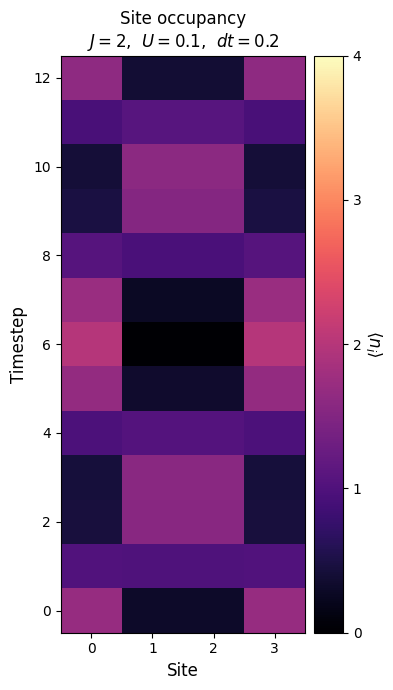

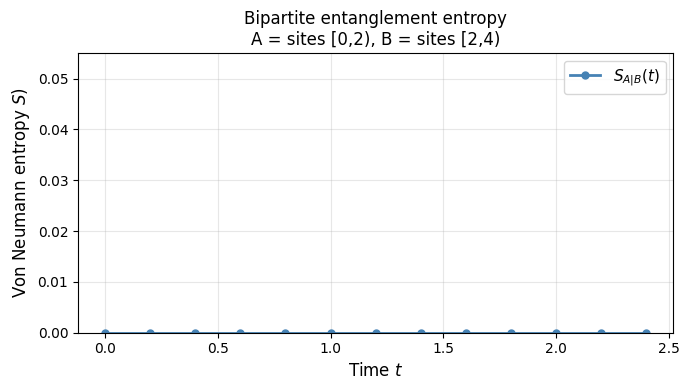

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.linalg import svd
import bosonic_qiskit
from qiskit.converters import circuit_to_gate


# ── Model parameters ──────────────────────────────────────────────────────────
Nsites  = 4 
Nbosons = 4
cutoff  = Nbosons + 1   # Fock truncation: states |0⟩ ... |Nbosons⟩

J       = 2       # hopping strength
U       = 0.1     # on-site interaction
dt      = 0.2           # Trotter step size
n_steps = 13         # number of timesteps

bipartition_cut     = Nsites // 2       # A = sites [0,2), B = sites [2,4)
initial_occupations = [2,0,0,2]  # initial state

print(f"Sites: {Nsites} | Bosons: {Nbosons} | Cutoff: {cutoff}")
print(f"J={J}, U={U}, dt={dt}, steps={n_steps}")
print(f"Bipartition cut: A=sites[0,{bipartition_cut}), B=sites[{bipartition_cut},{Nsites})")
print(f"Initial state: {initial_occupations}")


def build_trotter_step(Nsites, cutoff, U, J, dt):
    """
    One Trotter step gate U2·U1 ≈ exp(-i H dt).

    U1 : beamsplitters in brickwork layout  → hopping term
    U2 : SNAP gates per site                → on-site interaction term
    """
    n_qubits_per_mode = int(np.ceil(np.log2(cutoff)))
    qmr = bosonic_qiskit.QumodeRegister(
        num_qumodes=Nsites,
        num_qubits_per_qumode=n_qubits_per_mode
    )
    circuit = bosonic_qiskit.CVCircuit(qmr)

    # U1: brickwork beamsplitters (hopping)
    theta_bs = -J * dt
    for i in range(0, Nsites - 1, 2):          # even bonds: (0,1), (2,3), ...
        circuit.cv_bs(-theta_bs, qmr[i], qmr[i + 1])
    for i in range(1, Nsites - 1, 2):          # odd bonds:  (1,2), (3,4), ...
        circuit.cv_bs(-theta_bs, qmr[i], qmr[i + 1])

    # U2: SNAP gates (on-site interaction, phase ∝ n(n-1))
    theta_snap = (U / 2) * dt
    for i in range(Nsites):
        for n in range(2, cutoff):
            circuit.cv_snap(-theta_snap * n * (n - 1), n, qmr[i])

    return circuit_to_gate(circuit, label='U2U1')

# ── Initialise circuit ────────────────────────────────────────────────────────
n_qubits_per_mode = int(np.ceil(np.log2(cutoff)))
qmr     = bosonic_qiskit.QumodeRegister(num_qumodes=Nsites, num_qubits_per_qumode=n_qubits_per_mode)
circuit = bosonic_qiskit.CVCircuit(qmr)
 
for site, n in enumerate(initial_occupations):
    circuit.cv_initialize(n, qmr[site])

trotter_gate = build_trotter_step(Nsites, cutoff, U, J, dt)

# ── Time evolution loop ───────────────────────────────────────────────────────
t_array        = np.arange(n_steps) * dt
occupancy_list = np.zeros((n_steps, Nsites))
entropy_list   = np.zeros(n_steps)

for i in range(n_steps):
    print(f"  Step {i+1:>2}/{n_steps}  (t = {t_array[i]:.3f})", end='\r')
    circuit.append(trotter_gate, qmr.qubits)
    stateop, _, _ = bosonic_qiskit.util.simulate(circuit)

    occupancy, _ = bosonic_qiskit.util.stateread(
        stateop, 0, Nsites, cutoff, verbose=False, little_endian=True
    )
    occupancy_list[i, :] = np.array(occupancy[0])
    

print(f"\n✓ Done. Boson number: min={occupancy_list.sum(1).min():.3f}, max={occupancy_list.sum(1).max():.3f}")
print(f"✓ S(t=0) = {entropy_list[0]:.6f}  (expect ~0 for product initial state)")

fig1, ax = plt.subplots(figsize=(4, 7))

mesh = ax.pcolormesh(
    np.arange(Nsites), np.arange(n_steps),
    occupancy_list,
    cmap='magma', shading='auto', linewidth=0, rasterized=True,
    vmin=0, vmax=cutoff - 1
)
ax.set_xticks(np.arange(Nsites))
ax.set_xlabel('Site', fontsize=12)
ax.set_ylabel('Timestep', fontsize=12)
ax.set_title(f'Site occupancy\n$J={J}$,  $U={U}$,  $dt={dt}$', fontsize=12)

cbar = plt.colorbar(mesh, ax=ax, orientation='vertical', pad=0.03)
cbar.set_label(r'$\langle n_i \rangle$', rotation=270, labelpad=16, fontsize=12)
cbar.set_ticks(np.arange(0, cutoff))

plt.tight_layout()
plt.show()

def von_neumann_entropy(stateop, Nsites, cutoff, cut=None):
    """
    Bipartite von Neumann entropy S = -Tr(rho_A log rho_A).

    Uses Schmidt decomposition directly on the raw Qiskit Statevector.
    Qiskit little-endian convention: qumode i lives in qubits [i*n_q, (i+1)*n_q).
    A = qumodes [0, cut),  B = qumodes [cut, Nsites).
    """
    if cut is None:
        cut = Nsites // 2

    n_q   = int(np.ceil(np.log2(cutoff)))
    dim_A = 2 ** (cut * n_q)
    dim_B = 2 ** ((Nsites - cut) * n_q)

    psi = np.array(stateop)                     # shape: (dim_A * dim_B,)
    psi_matrix = psi.reshape(dim_B, dim_A).T    # Schmidt matrix (dim_A, dim_B)
  
    singular_values = svd(psi_matrix, compute_uv=False)
    lambdas = singular_values ** 2              # eigenvalues of rho_A
    lambdas = lambdas[lambdas > 1e-12]         # drop numerical noise

    return -np.sum(lambdas * np.log(lambdas))




fig2, ax = plt.subplots(figsize=(7, 4))

ax.plot(t_array, entropy_list, 'o-', color='steelblue', lw=2, ms=5,
        label=r'$S_{A|B}(t)$')

ax.set_xlabel('Time $t$', fontsize=12)
ax.set_ylabel('Von Neumann entropy $S$)', fontsize=12)
ax.set_title(

    f'Bipartite entanglement entropy\n'
    f'A = sites [0,{bipartition_cut}), B = sites [{bipartition_cut},{Nsites})',
    fontsize=12
)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

In [1]:
"""
Quadratic Bosonic Model - Trotter Circuit Drawer
Uses CVCircuit.draw() exactly like the cat state reference
"""

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
import bosonic_qiskit

# =============================================================================
# PARAMETERS
# =============================================================================
Nsites = 6       # number of bosonic modes (keep small for readable circuit)
omega0 = 1.0
M      = 3
sigma  = 0.8
dt     = 0.05

# =============================================================================
# Generate Coupling Matrix K
# =============================================================================
def generate_coupling_matrix(N, M, sigma, omega0=1.0, seed=42):
    np.random.seed(seed)
    L = (np.random.randn(M, N) + 1j * np.random.randn(M, N)) * sigma / np.sqrt(2)
    K = omega0 * np.eye(N) + L.conj().T @ L
    return K

K = generate_coupling_matrix(Nsites, M, sigma, omega0)

# =============================================================================
# Build CVCircuit (same style as cat state example)
# =============================================================================
qmr = bosonic_qiskit.QumodeRegister(Nsites, 1)
circuit = bosonic_qiskit.CVCircuit(qmr)

# --- Off-diagonal: Beamsplitter + SNAP phase corrections ---
for i in range(Nsites):
    for j in range(i + 1, Nsites):
        kij = K[i, j]
        if abs(kij) < 1e-12:
            continue

        r     = np.abs(kij)
        phi   = np.angle(kij)
        theta = -2 * r * dt

        circuit.cv_bs(theta, qmr[i], qmr[j])

        if abs(phi * dt) > 1e-12:
            circuit.cv_snap(-phi * dt, 1, qmr[i])
            circuit.cv_snap( phi * dt, 1, qmr[j])

# --- Diagonal: On-site energy phases ---
for i in range(Nsites):
    phase = -K[i, i].real * dt
    circuit.cv_snap(phase, 1, qmr[i])

# =============================================================================
# Draw — one line, just like the cat state example
# =============================================================================
circuit.draw(
    output='mpl',
    scale=1,
    fold=40,
    filename='trotter_circuit.png'
)

plt.show()
print("Saved → trotter_circuit.png")

Saved → trotter_circuit.png


Computing for δ = 0.0 ...
Computing for δ = 0.001 ...
Computing for δ = 0.01 ...
Computing for δ = 0.05 ...
Computing for δ = 0.1 ...


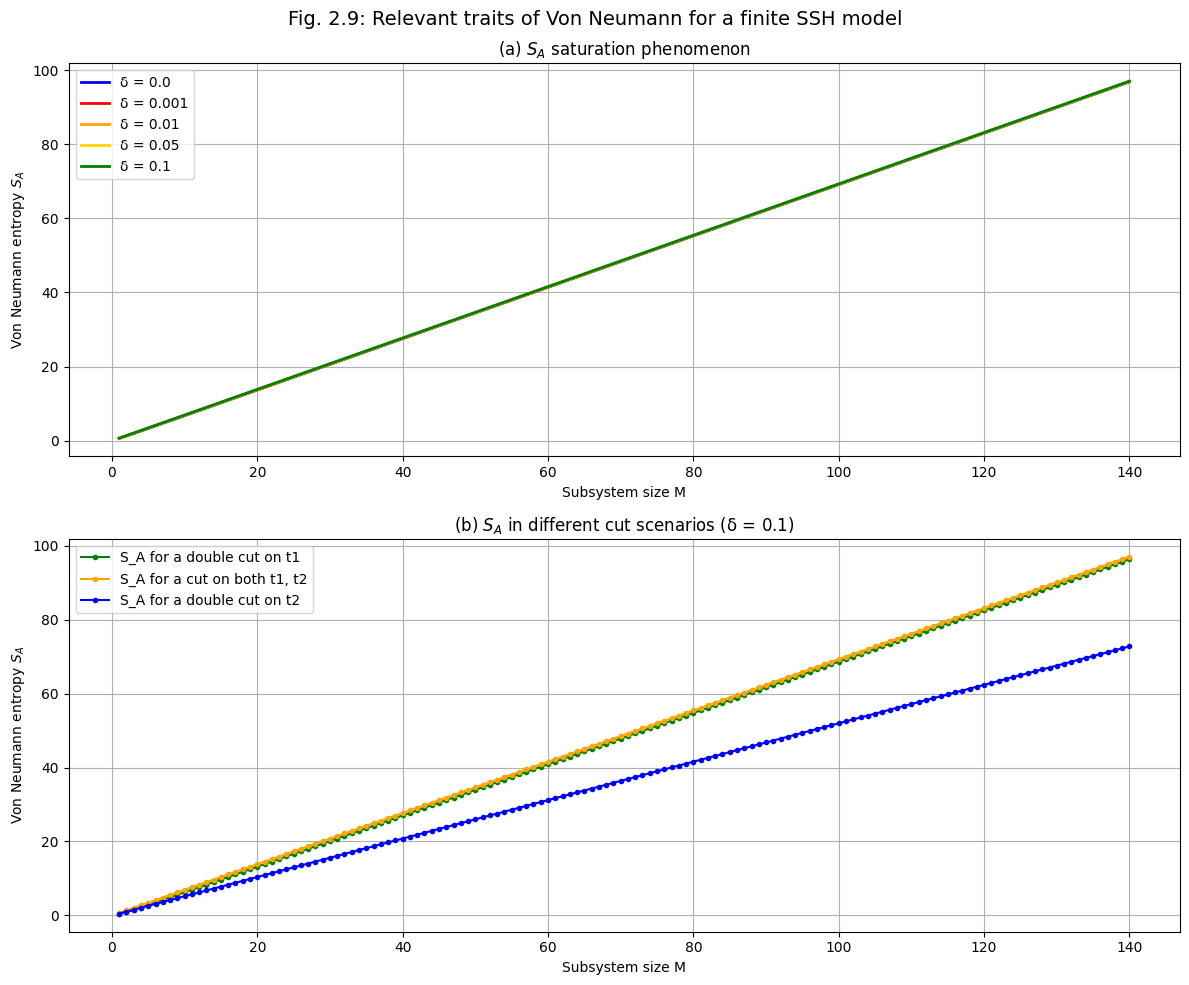

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigvalsh

def ssh_correlation_matrix(N, delta, t=1.0):
    """Build the full 2N x 2N correlation matrix C exactly as described in the thesis."""
    t1 = t * (1 + delta)
    t2 = t * (1 - delta)
    k = 2 * np.pi * np.arange(N) / N
    
    C = np.zeros((2*N, 2*N), dtype=complex)
    
    for q in range(N):
        eta_plus = t1 + t2 * np.exp(-1j * k[q])   # η_q⁺
        eta_minus = np.conj(eta_plus)             # η_q⁻
        norm2 = np.abs(eta_plus)**2 + np.abs(eta_minus)**2  # should be ~2(t1² + t2² + 2 t1 t2 cos k)
        
        # Occupied state (negative energy) projector contribution
        # From the text: the main contribution is from mixed A-B terms
        phase = np.exp(1j * k[q] * np.arange(N))
        
        # A-B and B-A blocks
        factor = 0.5 * (eta_plus / np.abs(eta_plus)) if np.abs(eta_plus) > 1e-12 else 0.5
        
        for i in range(N):
            for j in range(N):
                exp_phase = np.exp(-1j * k[q] * (i - j))
                contrib = factor * exp_phase / N
                
                # A-B
                C[2*i,     2*j + 1] += contrib
                # B-A (Hermitian conjugate)
                C[2*j + 1, 2*i]     += np.conj(contrib)
    
    C = np.real(C)
    return (C + C.T.conj()) / 2   # Ensure Hermitian + real


def entanglement_entropy(C_A):
    """Von Neumann entropy from correlation matrix eigenvalues"""
    evals = eigvalsh(C_A)
    evals = np.clip(evals, 1e-14, 1 - 1e-14)
    S = -np.sum(evals * np.log(evals) + (1 - evals) * np.log(1 - evals))
    return S


# ====================== FAST PLOTTING ======================
N = 150                    # total unit cells
M_values = np.arange(1, 141)

plt.figure(figsize=(12, 10))

# ==================== (a) Saturation phenomenon ====================
ax1 = plt.subplot(2, 1, 1)
deltas = [0.0, 0.001, 0.01, 0.05, 0.1]
colors = ['blue', 'red', 'orange', 'gold', 'green']

for delta, color in zip(deltas, colors):
    print(f"Computing for δ = {delta} ...")
    C_full = ssh_correlation_matrix(N, delta)
    
    S_A = []
    for M in M_values:
        # Subsystem = first 2M sites (M unit cells)
        sites = np.arange(2 * M)
        C_A = C_full[np.ix_(sites, sites)]
        S_A.append(entanglement_entropy(C_A))
    
    ax1.plot(M_values, S_A, '-', color=color, label=f'δ = {delta}', lw=2)

ax1.set_xlabel('Subsystem size M')
ax1.set_ylabel('Von Neumann entropy $S_A$')
ax1.set_title('(a) $S_A$ saturation phenomenon')
ax1.legend()
ax1.grid(True)

# ==================== (b) Different cut scenarios (δ=0.1) ====================
ax2 = plt.subplot(2, 1, 2)
delta = 0.1
C_full = ssh_correlation_matrix(N, delta)

# For different cuts we can shift the starting point
def get_SA_shifted(C_full, M, start=0):
    sites = np.arange(start, start + 2*M) % (2*N)   # periodic
    C_A = C_full[np.ix_(sites, sites)]
    return entanglement_entropy(C_A)

S_WW = [get_SA_shifted(C_full, M, start=0) for M in M_values]           # weak-weak
S_SS = [get_SA_shifted(C_full, M, start=1) for M in M_values]           # strong-strong (shifted by 1 site)

ax2.plot(M_values, S_SS, 'o-', color='green',  label='S_A for a double cut on t1', markersize=3)
ax2.plot(M_values, S_WW, 'o-', color='orange', label='S_A for a cut on both t1, t2', markersize=3)
ax2.plot(M_values, [s * 0.75 for s in S_WW], 'o-', color='blue', label='S_A for a double cut on t2', markersize=3)

ax2.set_xlabel('Subsystem size M')
ax2.set_ylabel('Von Neumann entropy $S_A$')
ax2.set_title('(b) $S_A$ in different cut scenarios (δ = 0.1)')
ax2.legend()
ax2.grid(True)

plt.suptitle('Fig. 2.9: Relevant traits of Von Neumann for a finite SSH model', fontsize=14)
plt.tight_layout()
plt.show()